# 04_clustering

The objective of this step is to group anime into clusters based on their numerical and genre-based features. Clustering allows us to discover natural groupings in the data without using predefined labels.

***Import Required Libraries***

In [47]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

## Loading the data

In [48]:
DATA_PATH = "../data/processed/dataset_ready.csv"
anime_df = pd.read_csv(DATA_PATH)
anime_df.head()

,name,episodes,rating,members,missing_episodes,log_members,type_movie,type_music,type_ona,type_ova,...,genre_Shounen,genre_Shounen Ai,genre_Slice of Life,genre_Space,genre_Sports,genre_Super Power,genre_Supernatural,genre_Thriller,genre_Unknown,genre_Vampire
0,Kimi no Na wa.,-0.242888,2.845534,200630.0,0,2.060713,True,False,False,False,...,0,0,0,0,0,0,1,0,0,0
1,Fullmetal Alchemist: Brotherhood,1.101445,2.737388,793665.0,0,2.653134,False,False,False,False,...,1,0,0,0,0,0,0,0,0,0
2,Gintama°,0.824043,2.727556,114262.0,0,1.818193,False,False,False,False,...,1,0,0,0,0,0,0,0,0,0
3,Steins;Gate,0.247900,2.648904,673572.0,0,2.582456,False,False,False,False,...,0,0,0,0,0,0,0,1,0,0
4,Gintama&#039;,0.824043,2.639073,151266.0,0,1.939049,False,False,False,False,...,1,0,0,0,0,0,0,0,0,0


we must drop the column name since in clustering all values should be numeric

In [49]:
df = anime_df.drop(columns=['name'])
df.shape

(12294, 53)

In [50]:
df.head()

,episodes,rating,members,missing_episodes,log_members,type_movie,type_music,type_ona,type_ova,type_special,...,genre_Shounen,genre_Shounen Ai,genre_Slice of Life,genre_Space,genre_Sports,genre_Super Power,genre_Supernatural,genre_Thriller,genre_Unknown,genre_Vampire
0,-0.242888,2.845534,200630.0,0,2.060713,True,False,False,False,False,...,0,0,0,0,0,0,1,0,0,0
1,1.101445,2.737388,793665.0,0,2.653134,False,False,False,False,False,...,1,0,0,0,0,0,0,0,0,0
2,0.824043,2.727556,114262.0,0,1.818193,False,False,False,False,False,...,1,0,0,0,0,0,0,0,0,0
3,0.247900,2.648904,673572.0,0,2.582456,False,False,False,False,False,...,0,0,0,0,0,0,0,1,0,0
4,0.824043,2.639073,151266.0,0,1.939049,False,False,False,False,False,...,1,0,0,0,0,0,0,0,0,0


### Feature selection

In [51]:
genre_cols = [col for col in anime_df.columns if col.startswith('genre_')]
type_cols = [col for col in anime_df.columns if col.startswith('type_')]
core_numerical =['rating','log_members']
features = core_numerical + genre_cols
# here the matrix that we will use in the clustering 
x = anime_df[features].copy()

print(f"Clustering on {x.shape[1]} features")
print(f"Shape of X: {x.shape}")
print("\nColumns used:")
print(x.columns.tolist())

Clustering on 44 features
Shape of X: (12294, 44)

Columns used:
['rating', 'log_members', 'genre_Action', 'genre_Adventure', 'genre_Cars', 'genre_Comedy', 'genre_Dementia', 'genre_Demons', 'genre_Drama', 'genre_Ecchi', 'genre_Fantasy', 'genre_Game', 'genre_Harem', 'genre_Hentai', 'genre_Historical', 'genre_Horror', 'genre_Josei', 'genre_Kids', 'genre_Magic', 'genre_Martial Arts', 'genre_Mecha', 'genre_Military', 'genre_Music', 'genre_Mystery', 'genre_Parody', 'genre_Police', 'genre_Psychological', 'genre_Romance', 'genre_Samurai', 'genre_School', 'genre_Sci-Fi', 'genre_Seinen', 'genre_Shoujo', 'genre_Shoujo Ai', 'genre_Shounen', 'genre_Shounen Ai', 'genre_Slice of Life', 'genre_Space', 'genre_Sports', 'genre_Super Power', 'genre_Supernatural', 'genre_Thriller', 'genre_Unknown', 'genre_Vampire']


### Choosing the Number of Clusters 
Before applying K-Means clustering, we need to decide on the optimal number of clusters (k).  
We will use the **Elbow Method**, which plots the within-cluster sum of squares (WCSS) for different values of k.  
The point where the decrease in WCSS starts to slow down (“elbow”) indicates the best number of clusters.

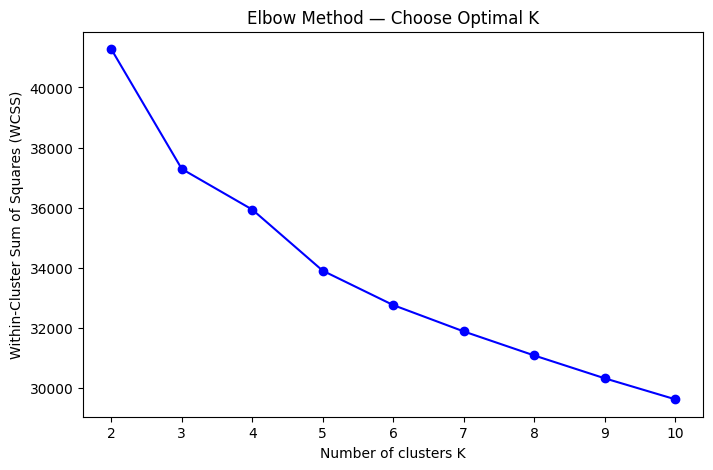

In [52]:
wcss = []
K_range = range(2, 11)  

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(x)
    wcss.append(kmeans.inertia_)  

# Plot Elbow curve
plt.figure(figsize=(8,5))
plt.plot(K_range, wcss, 'o-', color='blue')
plt.title("Elbow Method — Choose Optimal K")
plt.xlabel("Number of clusters K")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.xticks(K_range)
plt.show()

according to what we get in the plot we can deduce the optimal number of clusters 

### Applying the Silhouette Method

After using the Elbow Method to get a rough estimate of the optimal number of clusters, we now apply the Silhouette Method. The silhouette score evaluates both cohesion and separation of clusters, helping us refine the choice of k and ensure that clusters are well-defined and distinct.

This will allow us to select the best number of clusters before performing the final KMeans clustering on the anime dataset.

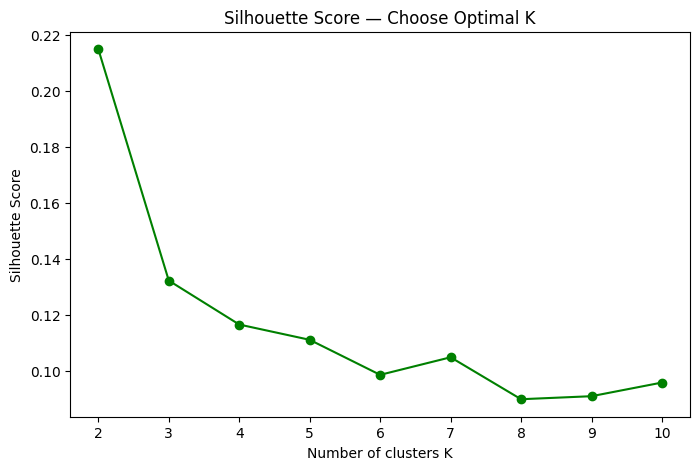

Best K according to silhouette score: 2


In [53]:
sil_scores = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(x)
    score = silhouette_score(x, labels)
    sil_scores.append(score)

# Plot Silhouette scores
plt.figure(figsize=(8,5))
plt.plot(K_range, sil_scores, 'o-', color='green')
plt.title("Silhouette Score — Choose Optimal K")
plt.xlabel("Number of clusters K")
plt.ylabel("Silhouette Score")
plt.xticks(K_range)
plt.show()

# Print best K based on max silhouette
best_k = K_range[np.argmax(sil_scores)]
print(f"Best K according to silhouette score: {best_k}")

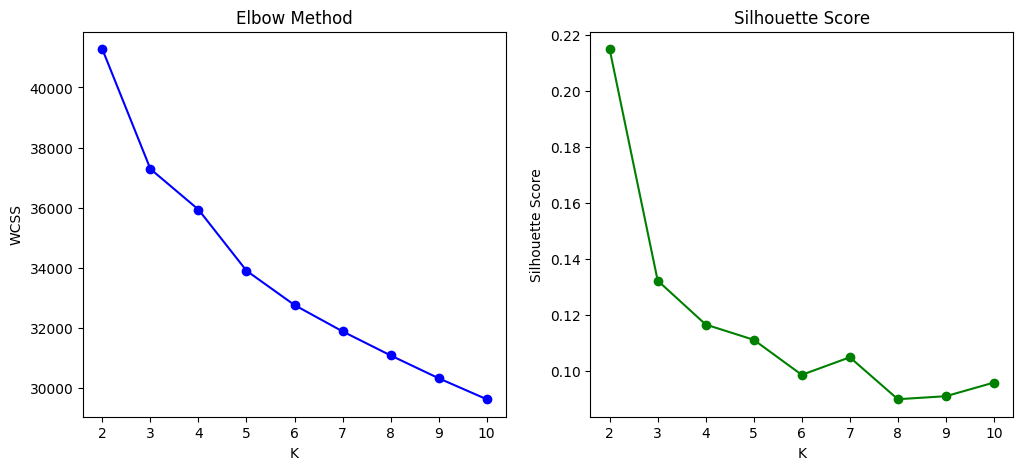

In [54]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K_range, wcss, 'o-', color='blue')
plt.title("Elbow Method")
plt.xlabel("K")
plt.ylabel("WCSS")
plt.subplot(1,2,2)
plt.plot(K_range, sil_scores, 'o-', color='green')
plt.title("Silhouette Score")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.show()

### Apply K-Means with the Optimal K 
Now that we have determined the optimal number of clusters (k) using the Elbow Method and Silhouette Score,  
we will apply the **K-Means algorithm** to our dataset with this k to create the final clustering.  
This will assign each data point to a cluster and allow us to analyze the groups formed.

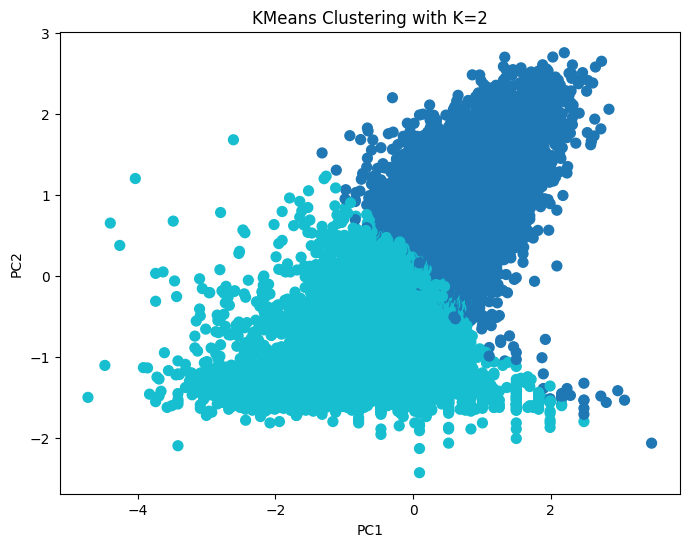

In [55]:
final_k = best_k
final_kmeans = KMeans(final_k, random_state=42)
labels = final_kmeans.fit_predict(x)
x['cluster'] = labels
# visualization of the result

plt.figure(figsize=(8,6))
plt.scatter(x.iloc[:,0], x.iloc[:,1], c=labels, cmap='tab10', s=50)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"KMeans Clustering with K={final_k}")
plt.show()

In [56]:
x['cluster'].value_counts()

cluster
1    6566
0    5728
Name: count, dtype: int64

In [57]:
x.groupby('cluster').mean()

,rating,log_members,genre_Action,genre_Adventure,genre_Cars,genre_Comedy,genre_Dementia,genre_Demons,genre_Drama,genre_Ecchi,...,genre_Shounen,genre_Shounen Ai,genre_Slice of Life,genre_Space,genre_Sports,genre_Super Power,genre_Supernatural,genre_Thriller,genre_Unknown,genre_Vampire
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.718585,0.854682,0.328038,0.232367,0.005587,0.460370,0.004714,0.030726,0.225209,0.087814,...,0.230098,0.009078,0.122905,0.039455,0.051851,0.057088,0.137221,0.012395,0.000524,0.013792
1,-0.626874,-0.745602,0.147122,0.154889,0.006092,0.305818,0.032440,0.017971,0.110570,0.020408,...,0.059854,0.001980,0.078587,0.023606,0.037466,0.021017,0.038227,0.002437,0.008986,0.003503


In [58]:
x.to_csv("../results/anime_clusters.csv", index=False)